# 第 48 课｜SciPy 厚尾收益与极端风险

本 Notebook 对应「365 天量化金融」第 48 课。课程方法来自本地完整视频、课件截图和本地 Whisper 口播整理；这里把它重建为默认离线、可核对、可重复执行的量化教学实现。

- 图文口播：`/Users/mojiawen/Documents/学习资料归档/_暂存/pam-video-captures/365-days-quant-finance/48_youtube-KeYUHIKJ6MY/index.html`
- 环境：`pkm-quant`
- 数据：固定随机种子的厚尾模拟收益；用于分布检验
- 状态：可运行学习稿；不代表策略收益承诺

> 网络接口和研究计算分离：Notebook 默认不请求第三方服务。真实接口只作为适配层示意，计算使用带来源声明的本地快照，避免限流、字段变化和历史数据重算破坏复现。

## 本节量化问题

正态模型用均值和标准差概括风险，但金融收益常见尖峰厚尾。这里比较 Normal Distribution（正态分布）、Student's t Distribution（学生 t 分布）和经验尾部计数。

In [1]:
from pathlib import Path
import json
import os
import platform
import sys
import tempfile
import timeit

# Matplotlib 首次运行需要写字体缓存；放到可写临时目录，避免污染用户目录。
MPL_CACHE_DIR = Path(tempfile.gettempdir()) / "pkm-quant-matplotlib"
MPL_CACHE_DIR.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str(MPL_CACHE_DIR))

import matplotlib.pyplot as plt
from matplotlib import font_manager
import numpy as np
import pandas as pd
import seaborn as sns

# 从本机字体中选择支持中文的字体，避免标题显示成方框。
preferred_chinese_fonts = [
    "PingFang SC",
    "Arial Unicode MS",
    "Hiragino Sans GB",
    "Heiti SC",
]
available_font_names = {font.name for font in font_manager.fontManager.ttflist}
chinese_font = next(
    (name for name in preferred_chinese_fonts if name in available_font_names),
    "DejaVu Sans",
)
plt.rcParams["font.sans-serif"] = [chinese_font, "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

def find_project_root():
    cwd = Path.cwd().resolve()
    candidates = [
        cwd,
        cwd / "实验" / "p2-python-toolchain",
        cwd / "p2-python-toolchain",
        *cwd.parents,
    ]
    for candidate in candidates:
        if (candidate / "课程辅助设计.md").exists():
            return candidate
    raise FileNotFoundError("请从 p2-python-toolchain 或量化交易项目目录启动 JupyterLab")

PROJECT_ROOT = find_project_root()
DATA_DIR = PROJECT_ROOT / "data" / "fixtures"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)
RANDOM_SEED = 365

print("Python:", sys.version.split()[0])
print("解释器:", sys.executable)
print("项目:", PROJECT_ROOT)
print("绘图字体:", chinese_font)

Python: 3.11.15
解释器: /opt/homebrew/Caskroom/miniforge/base/envs/pkm-quant/bin/python
项目: /Users/mojiawen/Documents/学习资料归档/_暂存/personal_knowledge_manager/量化交易/实验/p2-python-toolchain
绘图字体: PingFang SC


In [2]:
# 导入 SciPy 分布、拟合与检验工具。
from scipy import stats
print("SciPy stats ready")

SciPy stats ready


## 1. 先用已知自由度生成可重复厚尾样本

Student t 的自由度 `df` 越小尾越厚；`df <= 2` 时理论方差不存在。本例取 `df=4`，再缩放到约 1% 的日波动。

In [3]:
# 生成固定种子的厚尾收益，并计算标准化 z 分数。
rng = np.random.default_rng(365)
returns = pd.Series(stats.t.rvs(df=4, size=3000, random_state=rng) * 0.008, name="return")
z = (returns - returns.mean()) / returns.std(ddof=1)
summary = returns.describe(percentiles=[0.001, 0.01, 0.05, 0.95, 0.99, 0.999])
display(summary.to_frame())
print("样本超额峰度:", round(stats.kurtosis(returns, fisher=True), 3))
assert len(returns) == 3000
assert stats.kurtosis(returns, fisher=True) > 0

,return
count,3000.000000
mean,0.000125
std,0.010779
min,-0.079233
0.1%,-0.051512
1%,-0.028667
5%,-0.016255
95%,0.016971
99%,0.028362
99.9%,0.052964


样本超额峰度: 4.566


## 2. 拟合正态与 t 分布

- `stats.norm.fit` 返回 `loc, scale`；
- `stats.t.fit` 返回 `df, loc, scale`；
- 拟合参数来自同一样本，所以普通 K–S p 值只能作为诊断，不能当严格的“模型已被证明”。

In [4]:
# 拟合两种分布，并比较对数似然和经验分位数。
normal_loc, normal_scale = stats.norm.fit(returns)
t_df, t_loc, t_scale = stats.t.fit(returns)
ll_normal = stats.norm.logpdf(returns, normal_loc, normal_scale).sum()
ll_t = stats.t.logpdf(returns, t_df, t_loc, t_scale).sum()
fit_table = pd.DataFrame({
    "model": ["Normal", "Student-t"],
    "location": [normal_loc, t_loc],
    "scale": [normal_scale, t_scale],
    "df": [np.nan, t_df],
    "log_likelihood": [ll_normal, ll_t],
})
display(fit_table)
print("拟合 t 自由度:", round(t_df, 2))
assert t_df > 2

,model,location,scale,df,log_likelihood
0,Normal,0.000125,0.010777,NaN,9334.228906
1,Student-t,0.000131,0.008120,4.63504,9506.870831


拟合 t 自由度: 4.64


## 3. 直接比较 3σ 左尾的理论次数与实际次数

正态预测次数约为 `N × Φ(-3)`。实际计数来自标准化收益 `z < -3`。这比只看直方图更直接地暴露尾部低估。

In [5]:
# 计算正态理论次数、t 拟合次数和实际左尾事件数。
k = 3
n = len(z)
actual = int((z < -k).sum())
normal_expected = n * stats.norm.cdf(-k)
t_threshold = (returns.mean() - k * returns.std(ddof=1) - t_loc) / t_scale
t_expected = n * stats.t.cdf(t_threshold, t_df)
tail_table = pd.DataFrame({
    "口径": ["正态理论", "t 拟合", "实际样本"],
    "3σ左尾次数": [normal_expected, t_expected, actual],
})
display(tail_table)
assert actual >= 0

,口径,3σ左尾次数
0,正态理论,4.049694
1,t 拟合,18.328335
2,实际样本,21.000000


## 4. Bootstrap 给经验 1% 分位数一个不确定区间

Bootstrap 对原样本有放回重采样，每次计算 1% 分位数。区间反映有限样本估计误差，但不能创造样本中从未出现的危机机制。

In [6]:
# 用固定种子重复抽样，估计经验 1% VaR 分位数区间。
bootstrap_rng = np.random.default_rng(366)
quantiles = np.array([
    np.quantile(bootstrap_rng.choice(returns.to_numpy(), size=n, replace=True), 0.01)
    for _ in range(400)
])
interval = np.quantile(quantiles, [0.025, 0.5, 0.975])
print("1% 分位数 Bootstrap 95% 区间/中位数:", np.round(interval, 5))
assert interval[0] <= interval[1] <= interval[2]

1% 分位数 Bootstrap 95% 区间/中位数: [-0.03222 -0.02867 -0.0243 ]


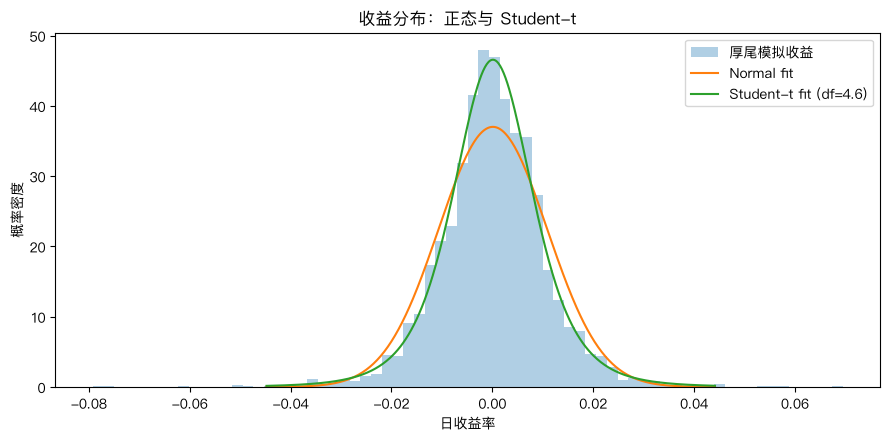

In [7]:
# 绘制经验密度与两种拟合密度，重点观察尾部而非只看中心。
x = np.linspace(returns.quantile(0.002), returns.quantile(0.998), 500)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(returns, bins=70, density=True, alpha=0.35, label="厚尾模拟收益")
ax.plot(x, stats.norm.pdf(x, normal_loc, normal_scale), label="Normal fit")
ax.plot(x, stats.t.pdf(x, t_df, t_loc, t_scale), label=f"Student-t fit (df={t_df:.1f})")
ax.set(title="收益分布：正态与 Student-t", xlabel="日收益率", ylabel="概率密度")
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "48_fat_tail_fit.png", dpi=150)
plt.show()

## 方法边界与复用结论


- 同样本估参后再做普通 K–S 检验会影响 p 值分布，严格检验需参数修正、Bootstrap 或样本外数据。
- 静态 t 分布仍不能表达波动聚集和成串危机事件。
- 风险报告应同时给经验分位数、尾部计数和压力情景，不能只给正态 VaR。


本课代码验证的是方法和数据契约，不是未来收益。迁移到真实研究前，还需重新核对来源授权、复权、时区、可得时间、交易成本和样本外边界。